**BIKE SHARING ANALYTICS**

**Analyse exploratoire de la demande de location de vélos**

**Projet portfolio Data Analyst**

Préparation :
1. Télécharger le jeu de données Bike Sharing (fichier journalier day.csv).
2. Placer day.csv dans le même dossier que ce script.
3. Installer les bibliothèques :
   pip install pandas numpy matplotlib seaborn

In [2]:
# Importation des bibliothèques
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Paramètre d'affichage
%matplotlib inline


#**1. Importation et contrôle des données**

In [5]:
import requests
import zipfile
import io

# URL du dataset
url = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"

# Télécharger le fichier
response = requests.get(url)

# Extraire le fichier zip
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    z.extractall()

# Chargement du fichier day.csv
df_day = pd.read_csv("day.csv")

# Afficher les 5 premières lignes du dataset
df_day.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [6]:
# Taille du dataset
print("Taille du dataset :", df.shape)

# Types des données et valeurs manquantes
df.info()

Taille du dataset : (731, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


Le jeu de données est composé de **731 observations et de 16 variables** et **chaque observation représente une journée de location de vélos**.

Il y a 3 types de données : **int64, float64 et object.**

**Il n'y a pas de valeurs manquantes**.

Notre variable cible **"cnt"** est de type int64.

In [8]:
# Statistiques descriptives
df_day.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


**Interprétation des statistiques descriptives**

La variable cnt, qui représente le nombre total de locations de vélos par jour, présente **une moyenne de 4 504 locations sur les 731 jours étudiés**.

**La médiane s'élève à 4 548 locations**, ce qui indique que la moitié des journées enregistre une fréquentation inférieure ou égale à cette valeur.

**L'écart-type de 1 937 locations** révèle une **dispersion importante** de la demande quotidienne. Les valeurs observées varient de **22 (min) à 8 714 (max) locations par jour**, mettant en évidence des écarts considérables entre les journées de faible et de forte fréquentation.

Sur le plan opérationnel, ces résultats soulignent l'importance d'adapter la disponibilité des vélos aux fluctuations de la demande. Une analyse complémentaire selon les saisons, les conditions météorologiques et les jours ouvrés permettra d'identifier les principaux facteurs associés à ces variations et d'améliorer la planification des ressources.

**Variables :**

Variable reponse : **cnt** (quantitative)

Variables explicatives :
- Variables quatitatives : **temp, hum, windspeed**

- Variables catégorielles : **season (1–4), weathersit, workingday (1 si jour ouvrable, 0 si week-end/jour férié)**

#**2. Analyse des distribuitions**

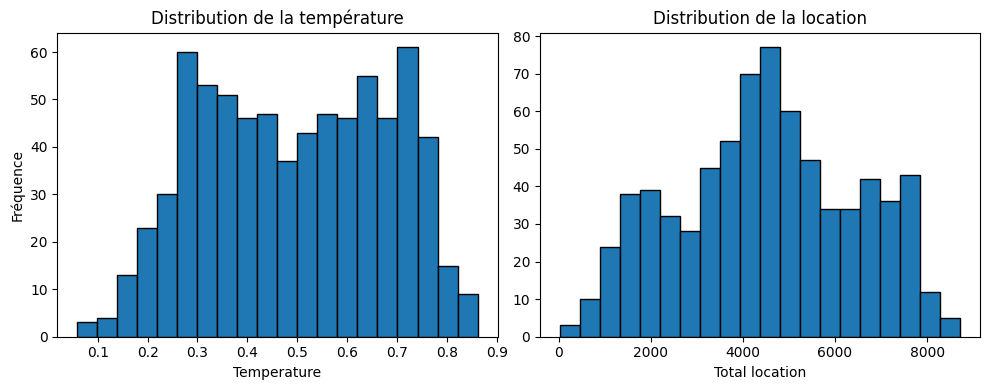

In [22]:
plt.figure(figsize=(10, 4))

# Distribution de la température
plt.subplot(1, 2, 1)
plt.hist(df_day["temp"], bins=20, edgecolor='black')
plt.title("Distribution de la température")
plt.xlabel("Temperature")
plt.ylabel("Fréquence")

# Distribution de la location
plt.subplot(1, 2, 2)
plt.hist(df_day["cnt"], bins=20, edgecolor='black')
plt.title("Distribution de la location")
plt.xlabel("Total location")

plt.tight_layout()
plt.show()

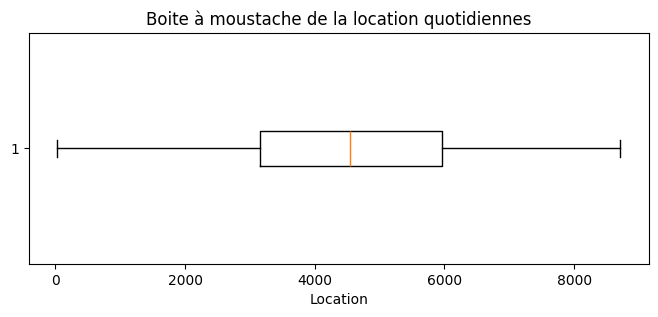

In [23]:
# Boite à moustache
plt.figure(figsize=(8, 3))

plt.boxplot(df_day["cnt"], vert=False)
plt.title("Boite à moustache de la location quotidiennes")
plt.xlabel("Location")
plt.show()

/tmp/ipykernel_968/45265904.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_day, x="season", y="cnt", palette="Set2")


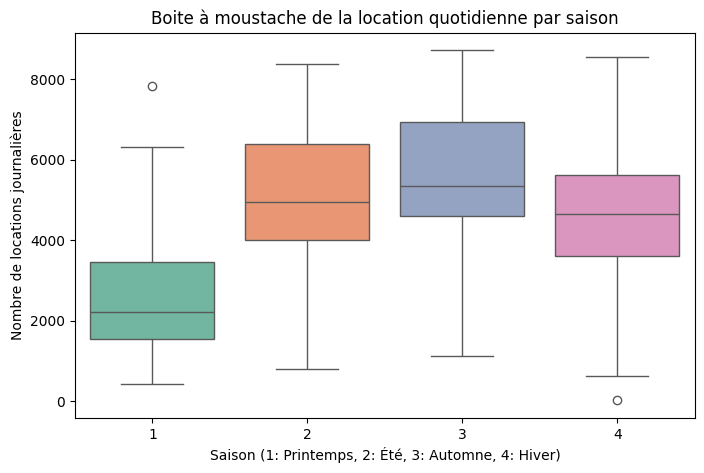

In [28]:
# Boite à moustache par saison
plt.figure(figsize=(8, 5))

sns.boxplot(data=df_day, x="season", y="cnt", palette="Set2")
plt.title("Boite à moustache de la location quotidienne par saison")
plt.xlabel("Saison (1: Printemps, 2: Été, 3: Automne, 4: Hiver)")
plt.ylabel("Nombre de locations journalières")
plt.show()

#**3. Analyse des tendances temporelles**

Objectif : comprendre comment évolue la demande de vélos dans le temps afin d'identifier les périodes de forte et de faible activité.

Cette étape est particulièrement importante pour un responsable des opérations : elle permet de mieux anticiper les besoins en vélos, en maintenance et en ressources humaines.

Question métier : à quelles périodes faut-il envisager d'augmenter la capacité opérationnelle ?

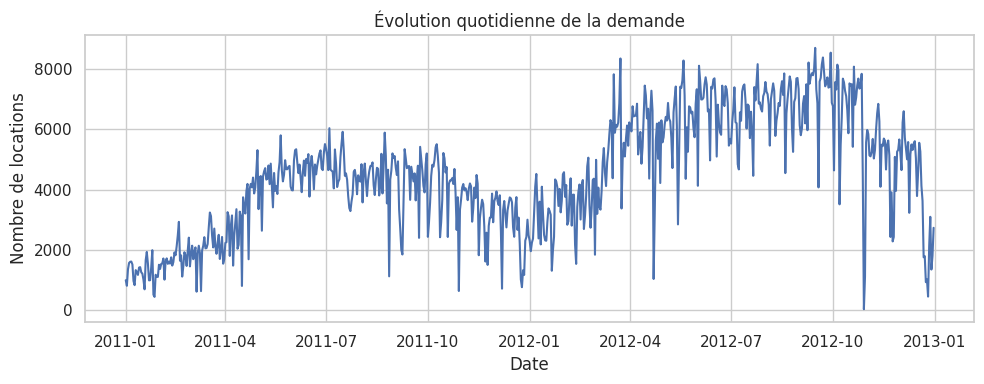

In [36]:
# Évolution quotidienne de la demande
plt.figure(figsize=(10, 4))

sns.lineplot(data=df_day, x="dteday", y="cnt")
plt.title("Évolution quotidienne de la demande")
plt.xlabel("Date")
plt.ylabel("Nombre de locations")
plt.tight_layout()
plt.show()

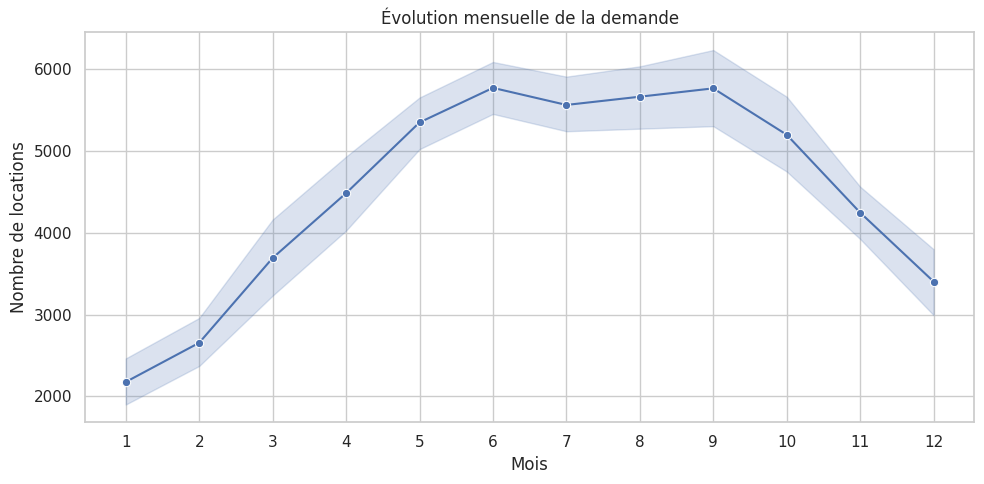

<Figure size 640x480 with 0 Axes>

In [67]:
# Évolution mensuelle de la demande
plt.figure(figsize=(10, 5))

sns.lineplot(data=df_day, x="mnth", y="cnt", marker="o")
plt.title("Évolution mensuelle de la demande")
plt.xlabel("Mois")
plt.ylabel("Nombre de locations")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()
plt.savefig("Demande_mensuelle.png")

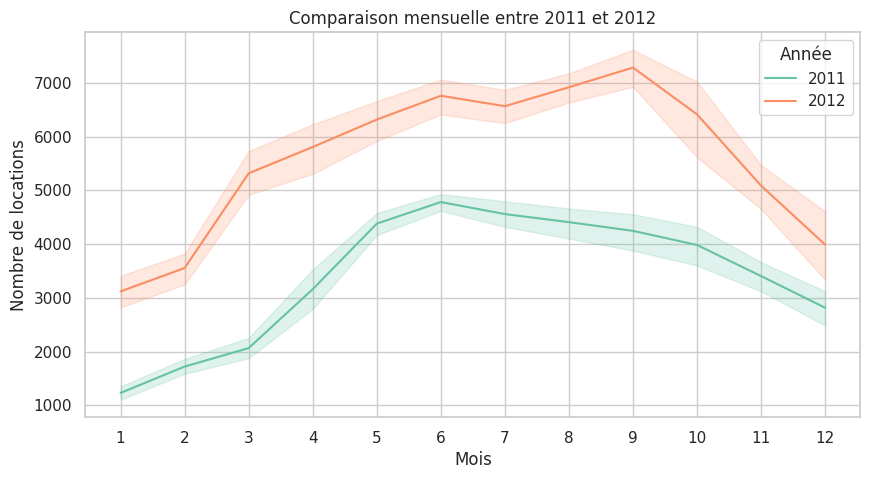

<Figure size 640x480 with 0 Axes>

In [69]:
# Comparaison mensuelle entre 2011 et 2012
plt.figure(figsize=(10, 5))

# Mapping des années 0 -> 2011 et 1 -> 2012 pour la légende
df_temp = df_day.copy()
df_temp["yr"] = df_temp["yr"].map({0: 2011, 1: 2012})

sns.lineplot(data=df_temp, x="mnth", y="cnt", hue="yr", palette="Set2")
plt.xticks(range(1, 13))
plt.title("Comparaison mensuelle entre 2011 et 2012")
plt.xlabel("Mois")
plt.ylabel("Nombre de locations")
plt.legend(title="Année")
plt.show()

#**4. Analyse des relations entre variables**

Objectif : étudier les relations entre les conditions météorologiques et la demande de vélos afin d'identifier les facteurs associés aux variations du nombre de locations.

Question métier : quelles variables méritent d'être prises en compte dans une future démarche de prévision de la demande ?

Pour cette étape, nous allons principalement étudier la relation entre cnt et trois variables météorologiques : **temp, hum et windspeed**

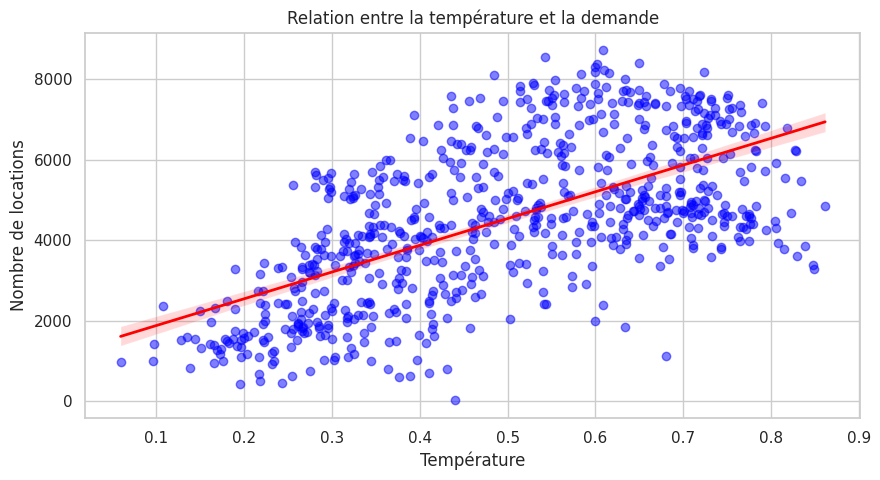

In [88]:
# Relation entre Température et demande
# observer si les locations augmentent avec la température.

plt.figure(figsize=(10, 5))

sns.regplot(data=df_day, x="temp", y="cnt", color="blue", scatter_kws={"alpha": 0.5}, line_kws={"color": "red", "linewidth": 2})
plt.title("Relation entre la température et la demande")
plt.xlabel("Température")
plt.ylabel("Nombre de locations")
plt.show()

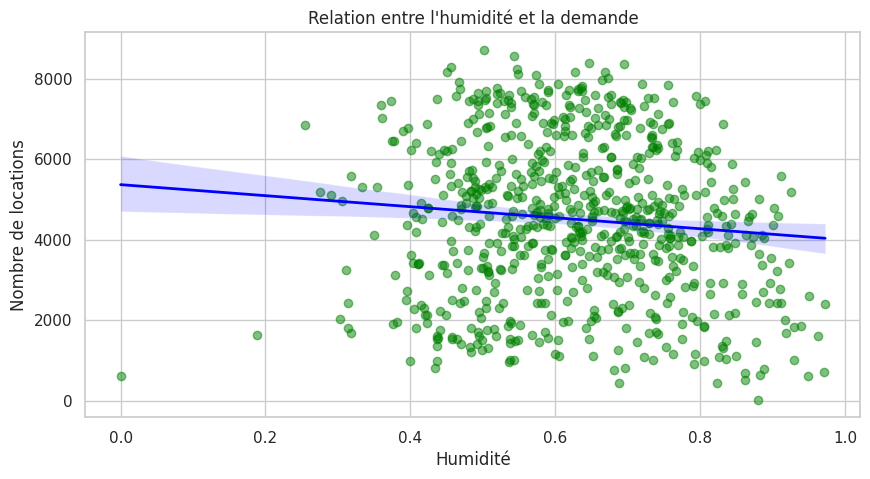

In [86]:
# Relation Humidité et demande : examiner l'association entre l'humidité et le niveau de fréquentation.

plt.figure(figsize=(10, 5))
sns.regplot(data=df_day, x="hum", y="cnt", color="green", scatter_kws={"alpha": 0.5}, line_kws={"color": "blue", "linewidth": 2})
plt.title("Relation entre l'humidité et la demande")
plt.xlabel("Humidité")
plt.ylabel("Nombre de locations")
plt.show()

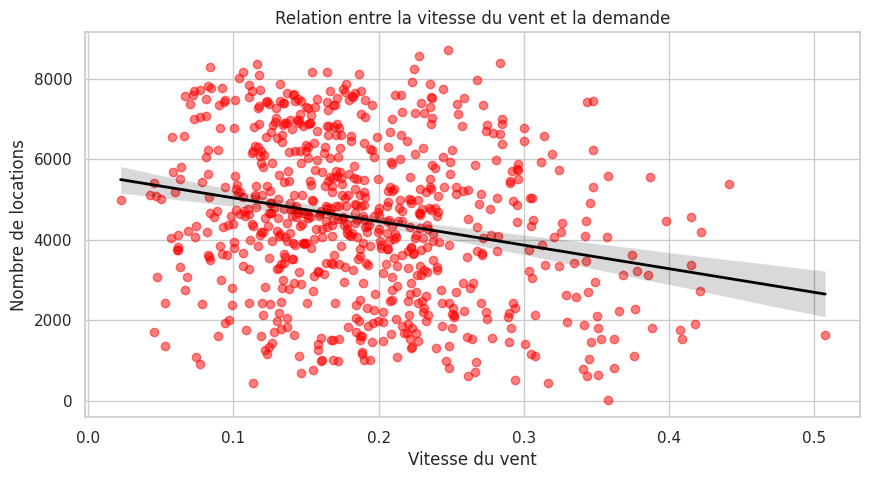

In [84]:
# Relation entre la vitesse du vent et et la demande

plt.figure(figsize=(10, 5))
sns.regplot(data=df_day, x="windspeed", y="cnt", color="red", scatter_kws={"alpha": 0.5}, line_kws={"color": "black", "linewidth": 2})
plt.title("Relation entre la vitesse du vent et la demande")
plt.xlabel("Vitesse du vent")
plt.ylabel("Nombre de locations")
plt.show()

#**5. Comparaison des groupes**

<function matplotlib.pyplot.show(close=None, block=None)>

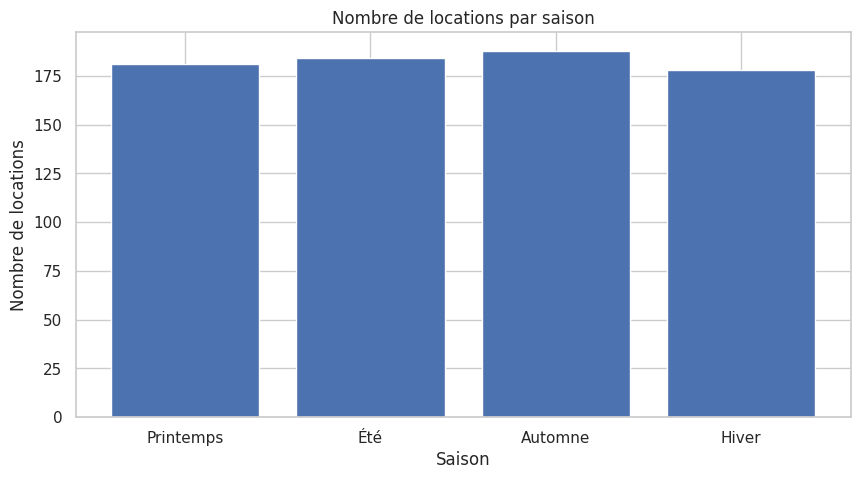

In [94]:
# Demande selon les saisons : identifier les saisons où la demande est la plus élevée.

plt.figure(figsize=(10, 5))
plt.bar(df_day["season"].value_counts().index, df_day["season"].value_counts())
plt.title("Nombre de locations par saison")
plt.xlabel("Saison")
plt.ylabel("Nombre de locations")
plt.xticks([1, 2, 3, 4], ["Printemps", "Été", "Automne", "Hiver"])
plt.show

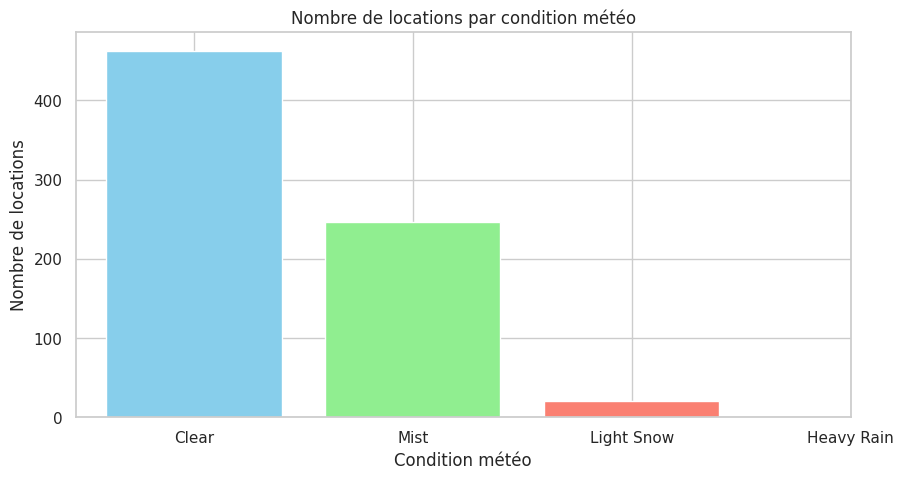

In [98]:
# Demande selon les conditions météorologiques : comparer la demande selon les différentes conditions météo.

plt.figure(figsize=(10, 5))
plt.bar(df_day["weathersit"].value_counts().index, df_day["weathersit"].value_counts(), color=["skyblue", "lightgreen", "salmon"])
plt.title("Nombre de locations par condition météo")
plt.xlabel("Condition météo")
plt.ylabel("Nombre de locations")
plt.xticks([1, 2, 3, 4], ["Clear", "Mist", "Light Snow", "Heavy Rain"])
plt.show()

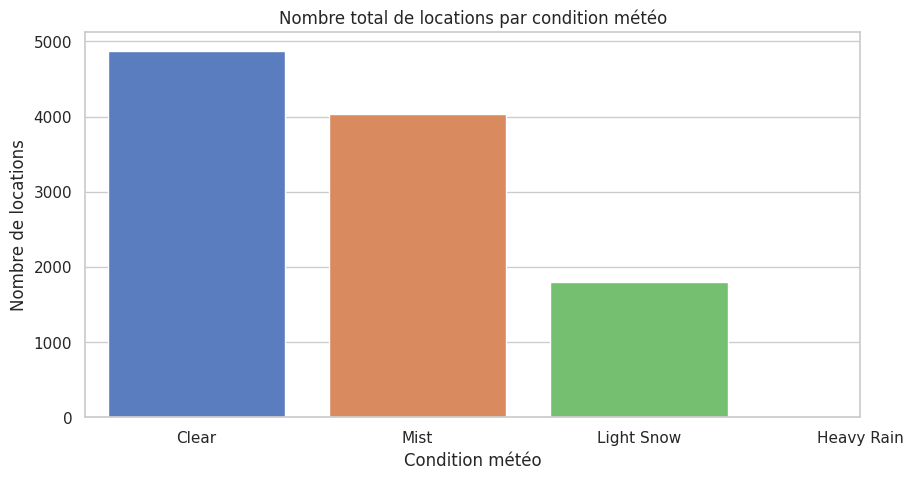

In [107]:
# Demande selon les conditions météorologiques : comparer la demande totale selon les conditions météo avec Seaborn barplot

plt.figure(figsize=(10, 5))
sns.barplot(data=df_day, x="weathersit", y="cnt", hue="weathersit", palette="muted", errorbar=None, legend=False)
plt.title("Nombre total de locations par condition météo")
plt.xlabel("Condition météo")
plt.ylabel("Nombre de locations")
plt.xticks([0, 1, 2, 3], ["Clear", "Mist", "Light Snow", "Heavy Rain"])
plt.show()

/tmp/ipykernel_968/2369277950.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_day, x="workingday", y="cnt", palette="Set2")


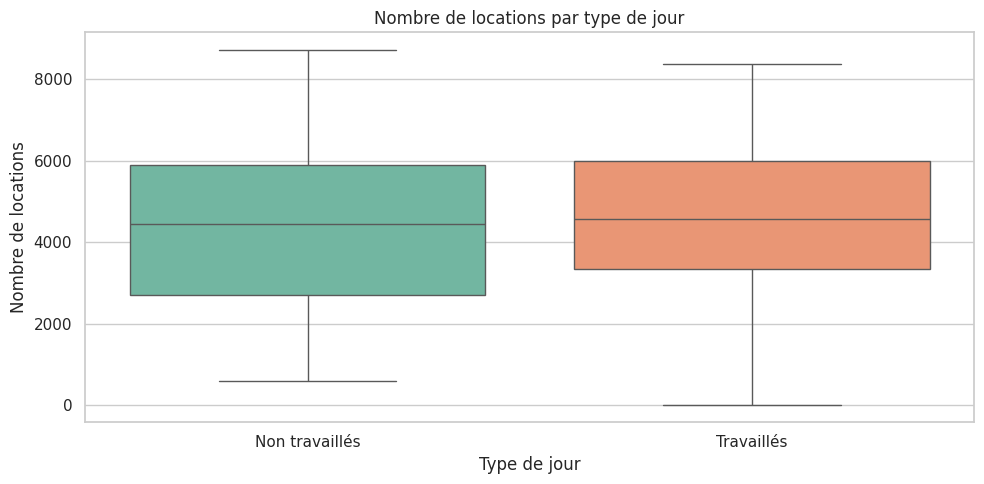

In [113]:
# Demande selon le type de jour : comparer la distribution de la demande entre jours travaillés et non travaillés.

plt.figure(figsize=(10, 5))
sns.boxplot(data=df_day, x="workingday", y="cnt", palette="Set2")
plt.title("Nombre de locations par type de jour")
plt.xlabel("Type de jour")
plt.ylabel("Nombre de locations")
plt.tight_layout()
plt.xticks([0, 1], ["Non travaillés", "Travaillés"])
plt.show()


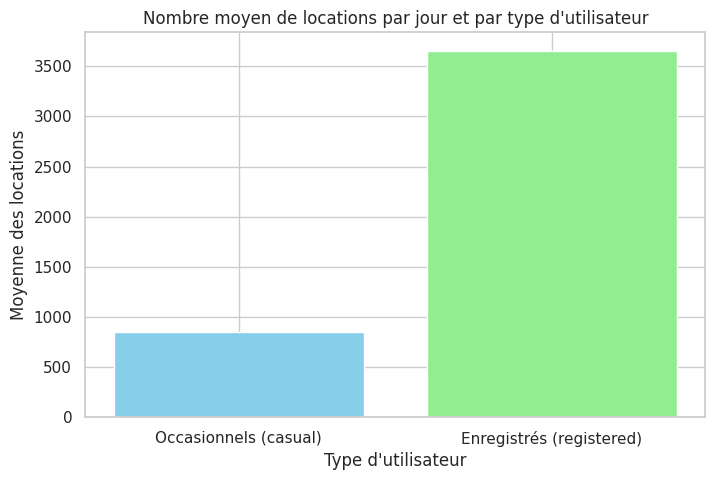

In [119]:
# Comparaison des profils d'utilisateurs : comparer l'activité moyenne des utilisateurs occasionnels et enregistrés.

# Calcul de la moyenne pour chaque type d'utilisateur
mean_casual = df_day["casual"].mean()
mean_registered = df_day["registered"].mean()

# Création du graphique en barres côte à côte
plt.figure(figsize=(8, 5))
plt.bar(["Occasionnels (casual)", "Enregistrés (registered)"], [mean_casual, mean_registered], color=["skyblue", "lightgreen"])
plt.title("Nombre moyen de locations par jour et par type d'utilisateur")
plt.xlabel("Type d'utilisateur")
plt.ylabel("Moyenne des locations")
plt.show()

In [ ]:
# Demande selon les saisons et la météo : examiner comment les conditions météorologiques sont associées à la demande au sein de chaque saison.


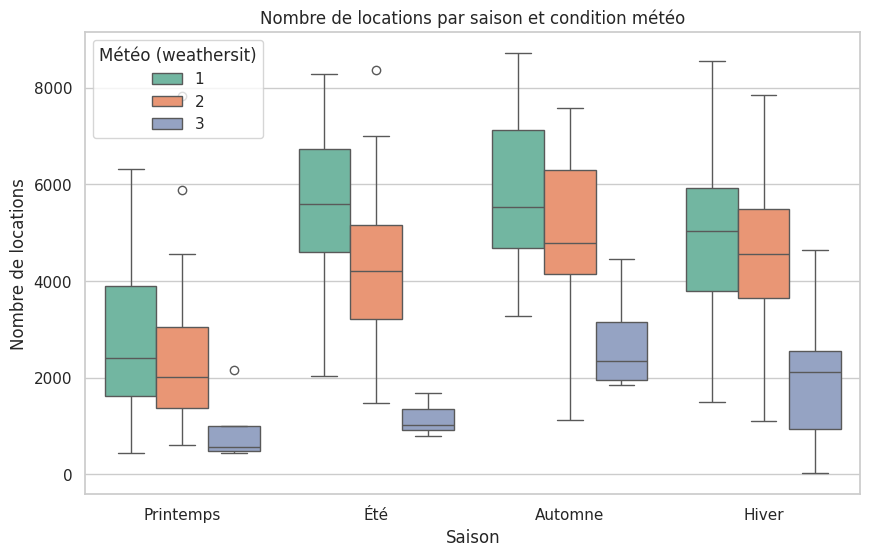

In [123]:
# Demande selon les saisons et la météo : examiner comment les conditions météorologiques sont associées à la demande au sein de chaque saison.

# Correction de plt.figsize en plt.figure(figsize=...)
plt.figure(figsize=(10, 6))

# Correction de sns.boxplot (suppression de errorbar, non supporté par boxplot)
sns.boxplot(data=df_day, x="season", y="cnt", hue="weathersit", palette="Set2")

plt.title("Nombre de locations par saison et condition météo")
plt.xlabel("Saison")
plt.ylabel("Nombre de locations")
plt.xticks([0, 1, 2, 3], ["Printemps", "Été", "Automne", "Hiver"])
plt.legend(title="Météo (weathersit)")
plt.show()

#**6. Analyse des corrélations**

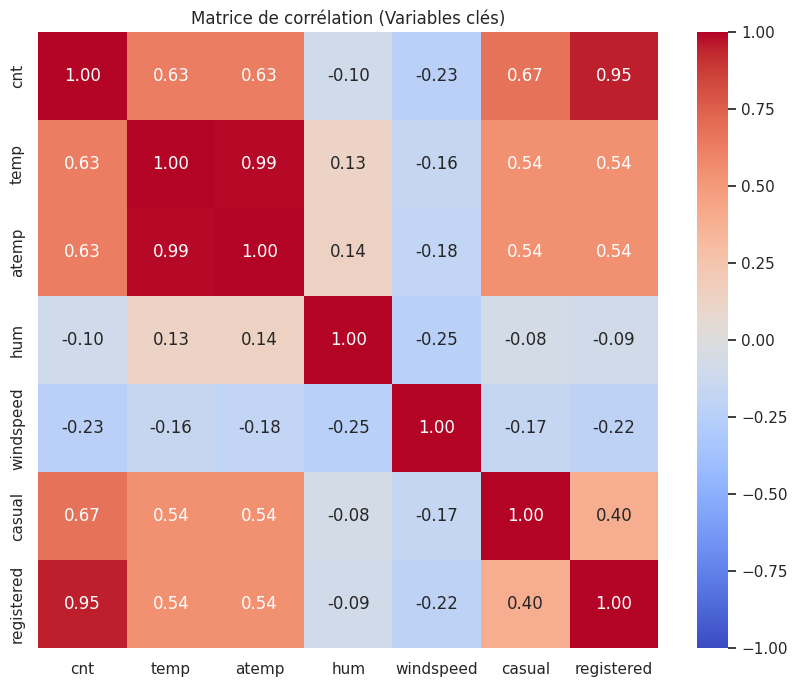

In [124]:
# Matrice de corrélation : synthétiser les associations linéaires entre les variables numériques sélectionnées.
selected_cols = ['cnt', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered']
# Les variables 'casual' et 'registered' dans la matrice de corrélation parce qu'elles permettent d'étudier la composition de la demande,
# et pas uniquement les facteurs météorologiques.
# casual : Mesure l'activité des clients non enregistrés.
# registered : Mesure l'activité des abonnés ou utilisateurs inscrits
corr_matrix = df_day[selected_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Matrice de corrélation (Variables clés)")
plt.show()

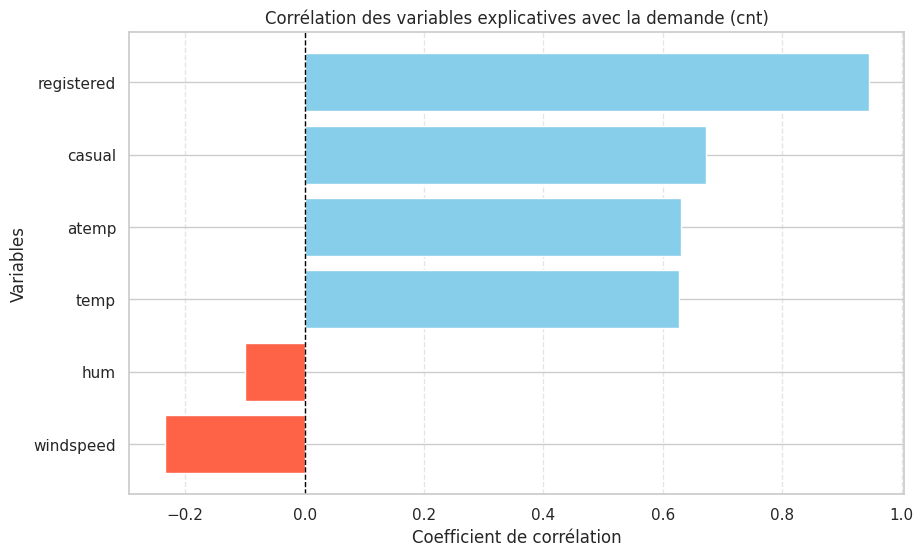

In [126]:
# Corrélation avec la demande (cnt) : classer les variables selon la force et le sens de leur association avec cnt.

# Extraction des corrélations par rapport à 'cnt' (en excluant 'cnt' lui-même)
correlations = corr_matrix["cnt"].drop("cnt").sort_values(ascending=True)

plt.figure(figsize=(10, 6))
colors = ["tomato" if val < 0 else "skyblue" for val in correlations.values]
plt.barh(correlations.index, correlations.values, color=colors)

plt.axvline(x=0, color="black", linestyle="--", linewidth=1)
plt.title("Corrélation des variables explicatives avec la demande (cnt)")
plt.xlabel("Coefficient de corrélation")
plt.ylabel("Variables")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.show()

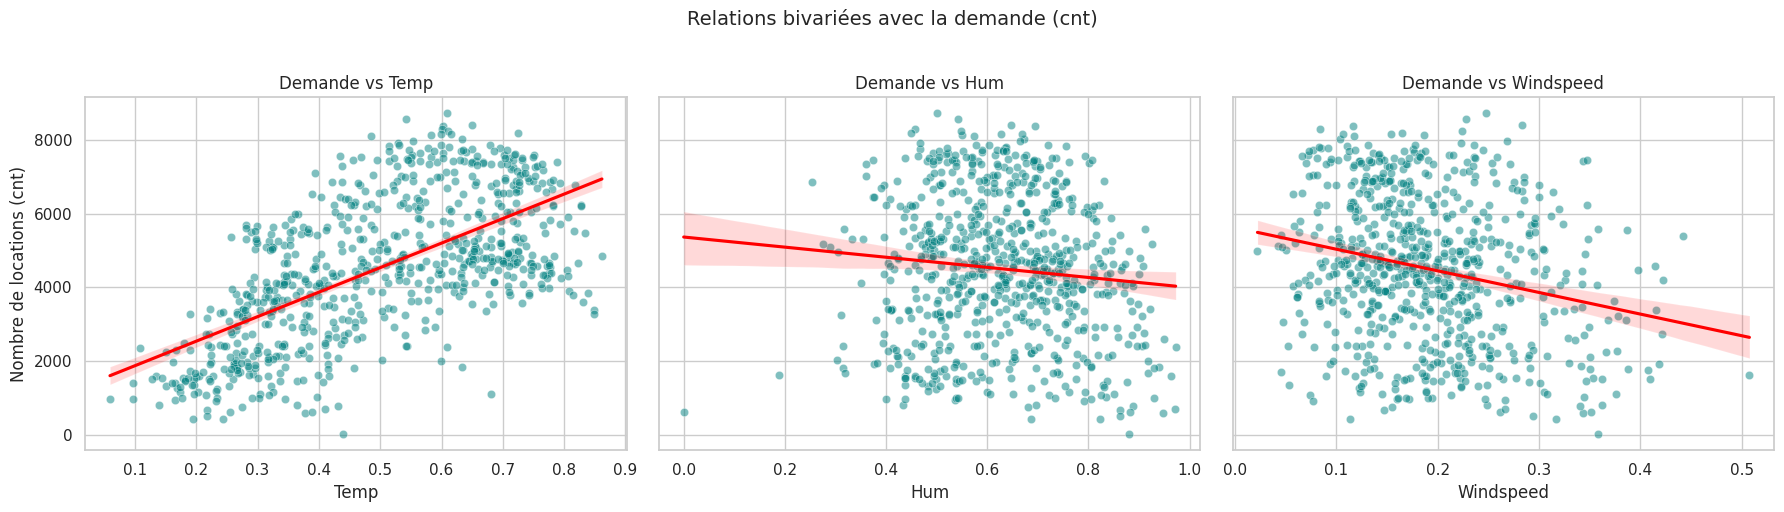

In [127]:
# Relations bivariées avec cnt : examiner visuellement les relations et repérer d'éventuelles formes non linéaires.

# Sélection des variables météo clés et de la variable cible 'cnt'
features = ["temp", "hum", "windspeed"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for i, col in enumerate(features):
    sns.scatterplot(data=df_day, x=col, y="cnt", ax=axes[i], alpha=0.5, color="teal")
    sns.regplot(data=df_day, x=col, y="cnt", ax=axes[i], scatter=False, color="red")
    axes[i].set_title(f"Demande vs {col.capitalize()}")
    axes[i].set_xlabel(col.capitalize())
    if i == 0:
        axes[i].set_ylabel("Nombre de locations (cnt)")

plt.suptitle("Relations bivariées avec la demande (cnt)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

#**7. Synthèse décisionnelle et recommandations métier**

In [128]:
import pandas as pd
import numpy as np

df_day = pd.read_csv("day.csv")

# 1. Indicateurs généraux
kpis = {
    "Demande moyenne": df_day["cnt"].mean(),
    "Demande médiane": df_day["cnt"].median(),
    "Demande maximale": df_day["cnt"].max(),
    "Demande minimale": df_day["cnt"].min(),
    "Ecart-type": df_day["cnt"].std(),
    "Coefficient de variation (%)":
        df_day["cnt"].std() / df_day["cnt"].mean() * 100
}

print("INDICATEURS GENERAUX")

for indicateur, valeur in kpis.items():
    print(f"{indicateur} : {valeur:.2f}")


# 2. Demande moyenne par saison
demande_saison = (
    df_day.groupby("season")["cnt"]
    .mean()
    .sort_values(ascending=False)
)

print("\nDEMANDE PAR SAISON")
print(demande_saison)


# 3. Demande moyenne par météo
demande_meteo = (
    df_day.groupby("weathersit")["cnt"]
    .mean()
    .sort_values(ascending=False)
)

print("\nDEMANDE PAR METEO")
print(demande_meteo)


# 4. Composition de la clientèle
total_locations = df_day["cnt"].sum()

part_casual = df_day["casual"].sum() / total_locations * 100
part_registered = df_day["registered"].sum() / total_locations * 100

print("\nCOMPOSITION DE LA CLIENTELE")
print(f"Occasionnels : {part_casual:.2f}%")
print(f"Enregistrés : {part_registered:.2f}%")

INDICATEURS GENERAUX
Demande moyenne : 4504.35
Demande médiane : 4548.00
Demande maximale : 8714.00
Demande minimale : 22.00
Ecart-type : 1937.21
Coefficient de variation (%) : 43.01

DEMANDE PAR SAISON
season
3    5644.303191
2    4992.331522
4    4728.162921
1    2604.132597
Name: cnt, dtype: float64

DEMANDE PAR METEO
weathersit
1    4876.786177
2    4035.862348
3    1803.285714
Name: cnt, dtype: float64

COMPOSITION DE LA CLIENTELE
Occasionnels : 18.83%
Enregistrés : 81.17%


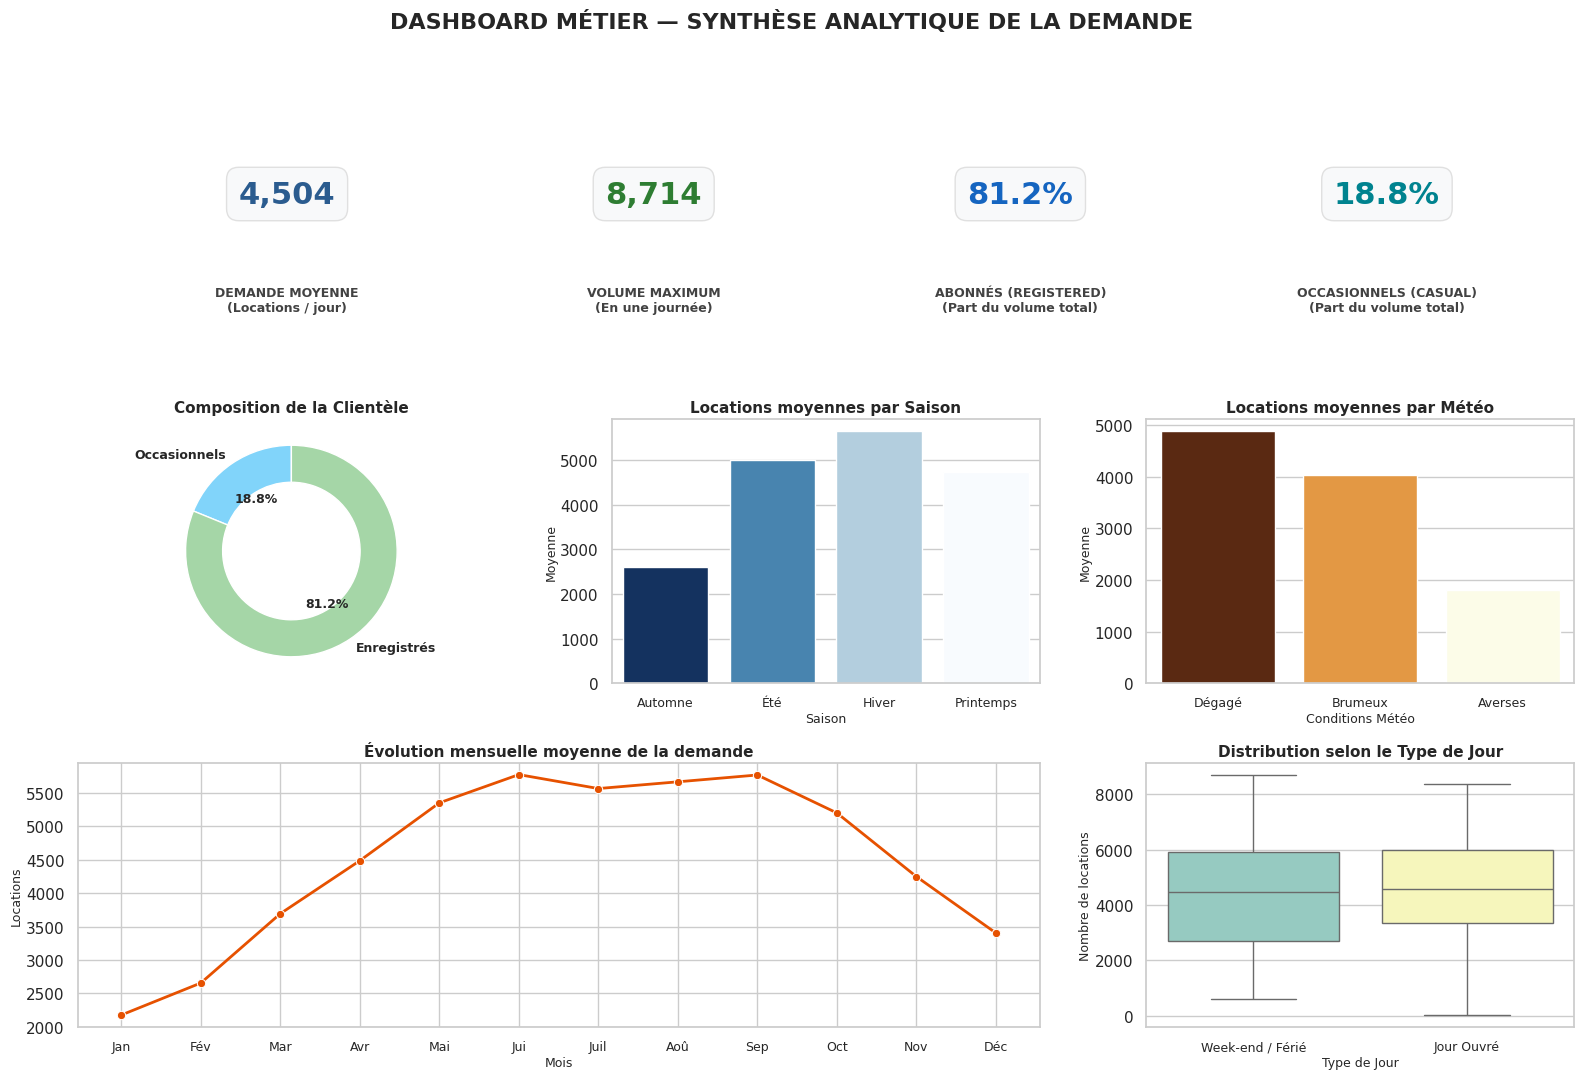

In [130]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration globale du style
sns.set_theme(style="whitegrid")
fig = plt.figure(figsize=(16, 11))
fig.suptitle("DASHBOARD MÉTIER — SYNTHÈSE ANALYTIQUE DE LA DEMANDE", fontsize=16, fontweight="bold", y=0.98)

# --- 1. Cartes d'indicateurs clés (KPIs) ---
ax_kpi = plt.subplot2grid((3, 3), (0, 0), colspan=3)
ax_kpi.axis("off")

kpi_data = [
    ("DEMANDE MOYENNE\n(Locations / jour)", f"{df_day['cnt'].mean():,.0f}", "#2b5c8f"),
    ("VOLUME MAXIMUM\n(En une journée)", f"{df_day['cnt'].max():,}", "#2e7d32"),
    ("ABONNÉS (REGISTERED)\n(Part du volume total)", f"{part_registered:.1f}%", "#1565c0"),
    ("OCCASIONNELS (CASUAL)\n(Part du volume total)", f"{part_casual:.1f}%", "#00838f")
]

for i, (label, val, col) in enumerate(kpi_data):
    x_pos = 0.04 + i * 0.245
    # Valeur numérique principale
    ax_kpi.text(x_pos + 0.1, 0.55, val, transform=ax_kpi.transAxes, fontsize=22, fontweight="bold", color=col, ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.4", facecolor="#f8f9fa", edgecolor="#e0e0e0", lw=1))
    # Libellé associé placé juste en dessous avec espacement minimal
    ax_kpi.text(x_pos + 0.1, 0.15, label, transform=ax_kpi.transAxes, fontsize=9, fontweight="bold", color="#424242", ha="center", va="center")

# --- 2. Répartition de la Clientèle (Pie Chart) ---
ax_pie = plt.subplot2grid((3, 3), (1, 0))
labels = ['Occasionnels', 'Enregistrés']
sizes = [part_casual, part_registered]
colors = ['#81d4fa', '#a5d6a7']
ax_pie.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90, colors=colors,
           textprops={'fontweight': 'bold', 'fontsize': 9}, wedgeprops=dict(width=0.35, edgecolor='w'))
ax_pie.set_title("Composition de la Clientèle", fontsize=11, fontweight="bold", pad=5)

# --- 3. Demande moyenne par Saison ---
ax_season = plt.subplot2grid((3, 3), (1, 1))
sns.barplot(x=demande_saison.index, y=demande_saison.values, palette="Blues_r", ax=ax_season, hue=demande_saison.index, legend=False)
ax_season.set_title("Locations moyennes par Saison", fontsize=11, fontweight="bold", pad=5)
ax_season.set_xticks(range(len(demande_saison)))
ax_season.set_xticklabels(["Automne", "Été", "Hiver", "Printemps"], fontsize=9)
ax_season.set_xlabel("Saison", fontsize=9, labelpad=2)
ax_season.set_ylabel("Moyenne", fontsize=9, labelpad=2)

# --- 4. Demande moyenne par Météo ---
ax_meteo = plt.subplot2grid((3, 3), (1, 2))
sns.barplot(x=demande_meteo.index, y=demande_meteo.values, palette="YlOrBr_r", ax=ax_meteo, hue=demande_meteo.index, legend=False)
ax_meteo.set_title("Locations moyennes par Météo", fontsize=11, fontweight="bold", pad=5)
ax_meteo.set_xticks(range(len(demande_meteo)))
ax_meteo.set_xticklabels(["Dégagé", "Brumeux", "Averses"], fontsize=9)
ax_meteo.set_xlabel("Conditions Météo", fontsize=9, labelpad=2)
ax_meteo.set_ylabel("Moyenne", fontsize=9, labelpad=2)

# --- 5. Tendance Mensuelle Globale (Nouveau Graphique) ---
ax_trend = plt.subplot2grid((3, 3), (2, 0), colspan=2)
monthly_avg = df_day.groupby("mnth")["cnt"].mean()
sns.lineplot(x=monthly_avg.index, y=monthly_avg.values, marker="o", color="#e65100", ax=ax_trend, linewidth=2)
ax_trend.set_title("Évolution mensuelle moyenne de la demande", fontsize=11, fontweight="bold", pad=5)
ax_trend.set_xticks(range(1, 13))
ax_trend.set_xticklabels(["Jan", "Fév", "Mar", "Avr", "Mai", "Jui", "Juil", "Aoû", "Sep", "Oct", "Nov", "Déc"], fontsize=9)
ax_trend.set_xlabel("Mois", fontsize=9, labelpad=2)
ax_trend.set_ylabel("Locations", fontsize=9, labelpad=2)

# --- 6. Impact Jours Ouvrés vs Week-end (Nouveau Graphique) ---
ax_work = plt.subplot2grid((3, 3), (2, 2))
sns.boxplot(data=df_day, x="workingday", y="cnt", palette="Set3", ax=ax_work, hue="workingday", legend=False)
ax_work.set_title("Distribution selon le Type de Jour", fontsize=11, fontweight="bold", pad=5)
ax_work.set_xticks([0, 1])
ax_work.set_xticklabels(["Week-end / Férié", "Jour Ouvré"], fontsize=9)
ax_work.set_xlabel("Type de Jour", fontsize=9, labelpad=2)
ax_work.set_ylabel("Nombre de locations", fontsize=9, labelpad=2)

# Ajustement optimisé de la disposition pour supprimer les grands espaces vides
plt.tight_layout()
plt.subplots_adjust(top=0.92, hspace=0.3, wspace=0.25)
plt.show()